In [1]:
# Data cleaning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
dataset = pd.read_csv("Iris.csv")
two_target = dataset[dataset["Species"] != 'Iris-virginica']
final_data = two_target.drop(columns="Id")
final_data.insert(loc=0,column="dummy-feature",value=1)
final_data
final_data["Species"] = final_data["Species"].map({"Iris-setosa":1,"Iris-versicolor":0})
data = final_data.to_numpy()
np.random.seed(42)
np.random.shuffle(data)
X = data[:, :-1]
Y = data[:, -1]
Y 
split_index = int(0.8 * len(data))
x_train = X[:split_index]
x_test = X[split_index:]
y_train = Y[:split_index]
y_test = Y[split_index:]

y_train.shape


(80,)

In [2]:
def sigmoid(z):
    """
    This is function to calculate the sigmoid given a value
    z = input scalar value 
    returns sig_value : scalar
    """
    import numpy as np
    sig_value = 1/(1+(np.exp(-z)))
    return sig_value

In [3]:
def predict(w,x):
    """
    This function is used to predict the value of target given input feature
    input parameters
    x = input feature
    w = weight of model
    output 
    prediction
    """
    prediction = sigmoid(w.T @ x)
    return prediction 

In [4]:
def cost(x,y,w):
    """
    This function returns the value for the cost 
    input parameters
    x: features shape(m,n),m = number of data points, n = number features + 1(dummy)
    y: targets  shape(m,) 
    w: weights shape(n)
    output = cost
    """
    import numpy as np
    cost = 0
    for i in range(len(x)):
        value = predict(w,x[i])
        cost += -((y[i] * np.log(value)) + (1-y[i])*np.log(1-value))
    cost = cost/len(x)
    return cost
    

In [5]:
def gradient(w,x,y):
    """
    This function calculates the gradient
    w = weight
    x = input feature
    y = target
    output = gradient
    """
    import numpy as np
    gradient = np.zeros(x.shape[1])
    for i in range(len(x)):
        error = ((predict(w,x[i])) - y[i])
        gradient += error * x[i]
    gradient = gradient/len(x)
    return gradient


In [6]:
def gradient_descent(w,x,step_size,num_iters,y):
    """
    this function implements the gradient descent algorithm
    input parameters 
    x = input features
    w = initial weights
    step_size 
    num_iters
    output 
    final_w 
    """
    track_cost = []
    for i in range(num_iters):
        w = w - step_size * gradient(w,x,y)
        cost_ = cost(x,y,w)
        track_cost.append(cost_)
    return w , track_cost

In [7]:
w_in = np.zeros(x_train.shape[1])
final_weight, cost_value = gradient_descent(w_in,x_train,0.1,1000,y_train)
final_weight

array([ 0.34568471,  0.55213849,  2.00407655, -3.07394052, -1.36330963])

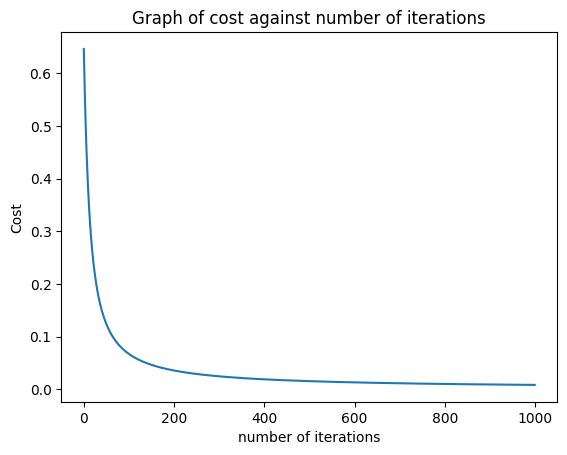

In [8]:
fig,ax = plt.subplots()
ax.set_xlabel("number of iterations")
ax.set_ylabel("Cost")
ax.set_title("Graph of cost against number of iterations")
ax.plot(cost_value)


In [9]:
def model_accuracy(x,y,w):
    """
    This function calculates the accuracy of the model based on test data
    """
    import numpy as np
    probabilities = sigmoid(x @ w)
    predictions = (probabilities >= 0.5).astype(int)
    correct_pred = np.sum(predictions == y_test)
    percentage = correct_pred/len(y_test) * 100
    return f'{percentage}%'

In [10]:
print(model_accuracy(x_test,y_test,final_weight))


100.0%
